# 01 - Exploratory data analysis

Research window 2009-01-01 to 2023-12-29. Every figure ends with the finding and the decision it changes; this is the PRD Section 6 requirement. The notebook calls the versioned `src/` code rather than duplicating the pipeline.

In [1]:
import sys
from pathlib import Path

root = Path.cwd()
while not (root / 'src').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from scipy.stats import skew, kurtosis
from src.utils import load_config, path_from_config

cfg = load_config()
P = path_from_config(cfg, 'processed')
F = path_from_config(cfg, 'figures')
F.mkdir(parents=True, exist_ok=True)
prices = pd.read_parquet(P / 'prices_clean.parquet')
macro = pd.read_parquet(P / 'macro_clean.parquet')
panel = pd.read_parquet(P / 'panel.parquet')
equities = cfg['universe']['equities']
prices.shape, panel.shape

((75480, 12), (35640, 72))

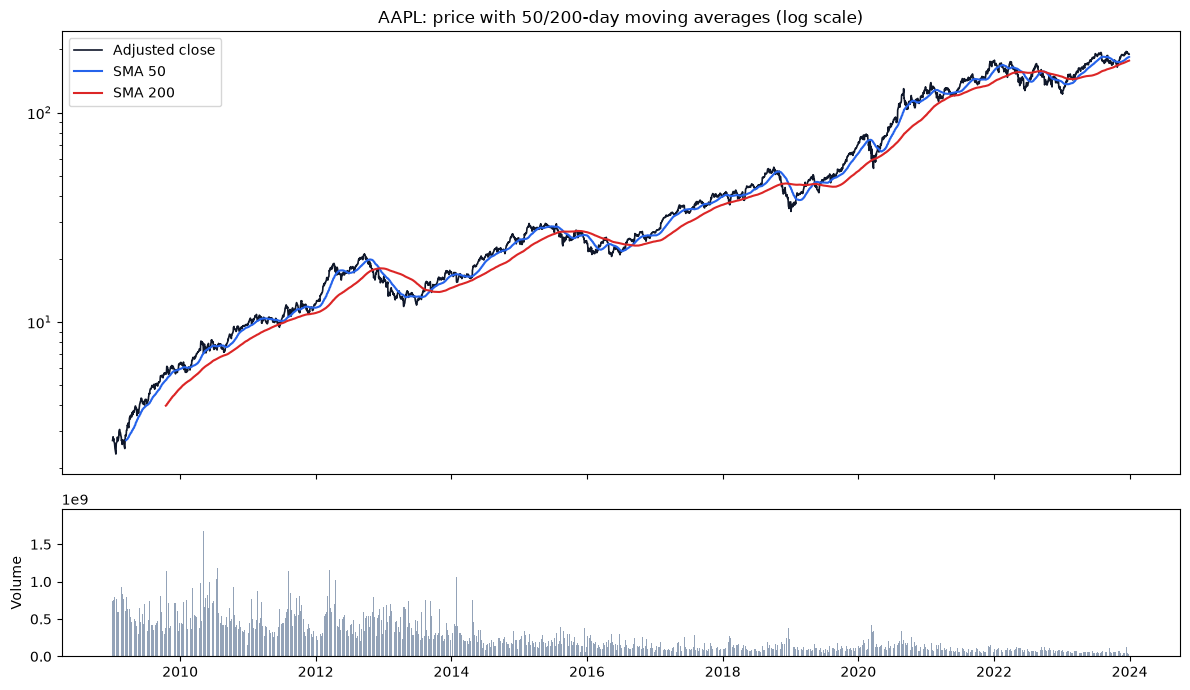

In [2]:
ticker = 'AAPL'
g = prices[prices['ticker'] == ticker].set_index('date')
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax[0].plot(g.index, g['adj_close'], label='Adjusted close', color='#0f172a', linewidth=1.2)
ax[0].plot(g.index, g['adj_close'].rolling(50).mean(), label='SMA 50', color='#2563eb')
ax[0].plot(g.index, g['adj_close'].rolling(200).mean(), label='SMA 200', color='#dc2626')
ax[0].set_yscale('log')
ax[0].set_title(f'{ticker}: price with 50/200-day moving averages (log scale)')
ax[0].legend(loc='upper left')
ax[1].bar(g.index, g['volume'], color='#94a3b8', width=1.0)
ax[1].set_ylabel('Volume')
fig.tight_layout()
fig.savefig(F / 'eda_trend.png', dpi=150, bbox_inches='tight')
plt.show()

**Finding.** The adjusted series trends strongly and the 200-day average only crosses the 50-day average in regime changes. **Consequence.** Raw price is non-stationary; the model must forecast log returns, not price, and trend features enter as price-to-MA ratios.

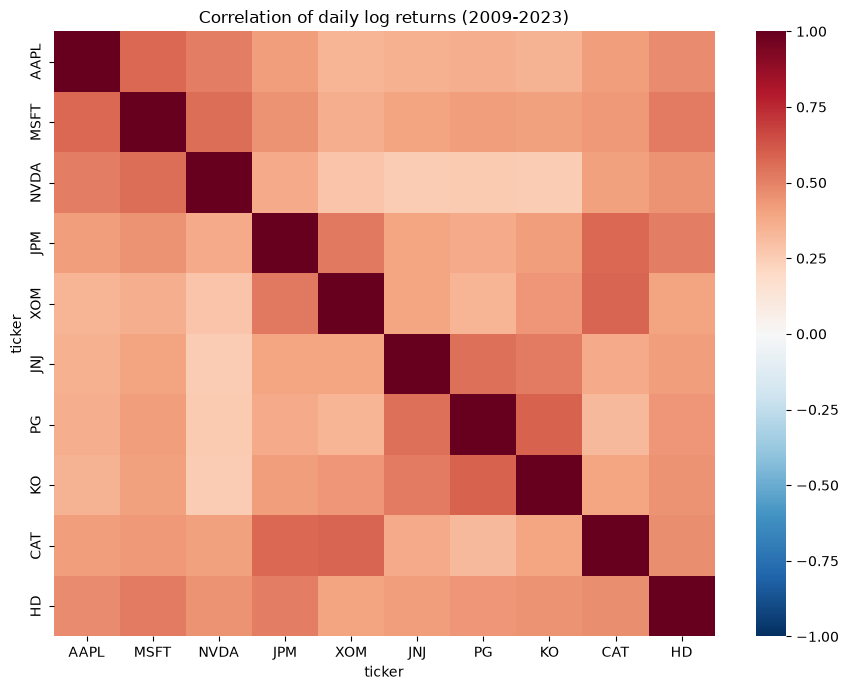

ticker,AAPL,MSFT,NVDA,JPM,XOM,JNJ,PG,KO,CAT,HD
ticker,,,,,,,,,,
AAPL,1.00,0.58,0.51,0.42,0.34,0.35,0.36,0.35,0.42,0.48
MSFT,0.58,1.00,0.56,0.45,0.37,0.40,0.41,0.41,0.44,0.52
NVDA,0.51,0.56,1.00,0.38,0.29,0.25,0.26,0.25,0.41,0.45
JPM,0.42,0.45,0.38,1.00,0.53,0.39,0.38,0.42,0.57,0.51
XOM,0.34,0.37,0.29,0.53,1.00,0.40,0.34,0.44,0.58,0.41
JNJ,0.35,0.40,0.25,0.39,0.40,1.00,0.55,0.52,0.38,0.42
PG,0.36,0.41,0.26,0.38,0.34,0.55,1.00,0.59,0.33,0.44
KO,0.35,0.41,0.25,0.42,0.44,0.52,0.59,1.00,0.40,0.45
CAT,0.42,0.44,0.41,0.57,0.58,0.38,0.33,0.40,1.00,0.47


In [3]:
wide = prices.pivot_table(index='date', columns='ticker', values='log_return')[equities]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(wide.corr(), cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=False, ax=ax)
ax.set_title('Correlation of daily log returns (2009-2023)')
fig.tight_layout()
fig.savefig(F / 'eda_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
wide.corr().round(2)

**Finding.** Correlations are positive but mostly below 0.6, so the 10-name universe offers genuine diversification. **Consequence.** The covariance matrix is well conditioned, and a long-only max-Sharpe portfolio can add value over a single name.

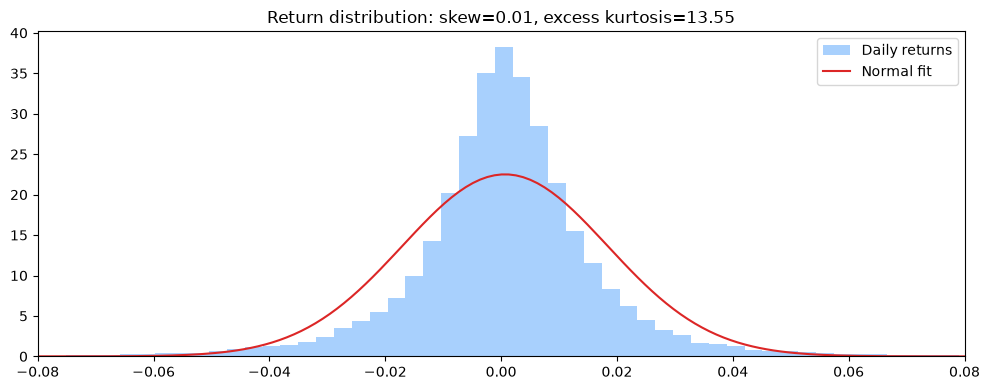

(np.float64(0.013463538070657978), np.float64(13.553202912275669))

In [4]:
r = wide.stack().dropna().to_numpy()
mu, sd = r.mean(), r.std()
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(r, bins=160, density=True, color='#93c5fd', alpha=0.8, label='Daily returns')
x = np.linspace(r.min(), r.max(), 400)
ax.plot(x, (1 / (sd * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu) / sd) ** 2), color='#dc2626', label='Normal fit')
ax.set_title(f'Return distribution: skew={skew(r):.2f}, excess kurtosis={kurtosis(r):.2f}')
ax.set_xlim(-0.08, 0.08)
ax.legend()
fig.tight_layout()
fig.savefig(F / 'eda_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
(skew(r), kurtosis(r))

**Finding.** Returns are fat-tailed and slightly skewed. **Consequence.** Risk reporting never relies only on the normal assumption: drawdown, historical VaR and a Student-t parametric VaR are reported alongside volatility, and Huber loss is used for the neural nets.

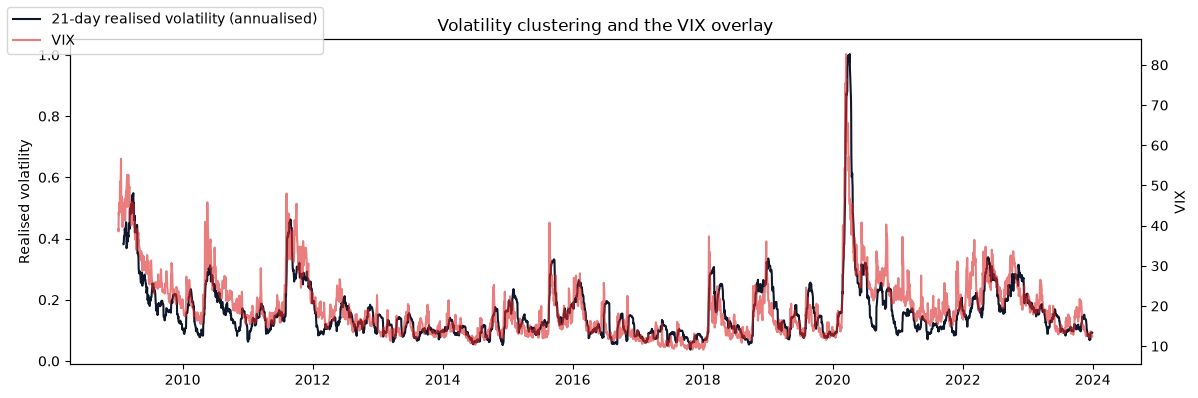

In [5]:
port = wide.mean(axis=1)
vol = port.rolling(21).std() * np.sqrt(252)
vix = prices[prices['ticker'] == '^VIX'].set_index('date')['adj_close'].reindex(port.index).ffill()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(vol.index, vol, label='21-day realised volatility (annualised)', color='#0f172a')
ax2 = ax.twinx()
ax2.plot(vix.index, vix, label='VIX', color='#dc2626', alpha=0.6)
ax.set_ylabel('Realised volatility')
ax2.set_ylabel('VIX')
ax.set_title('Volatility clustering and the VIX overlay')
fig.legend(loc='upper left')
fig.tight_layout()
fig.savefig(F / 'eda_volatility.png', dpi=150, bbox_inches='tight')
plt.show()

**Finding.** Volatility clusters and co-moves with the VIX. **Consequence.** VIX level/change, rolling volatility and beta are included as regime features, and the risk dashboard shows rolling volatility against the VIX.

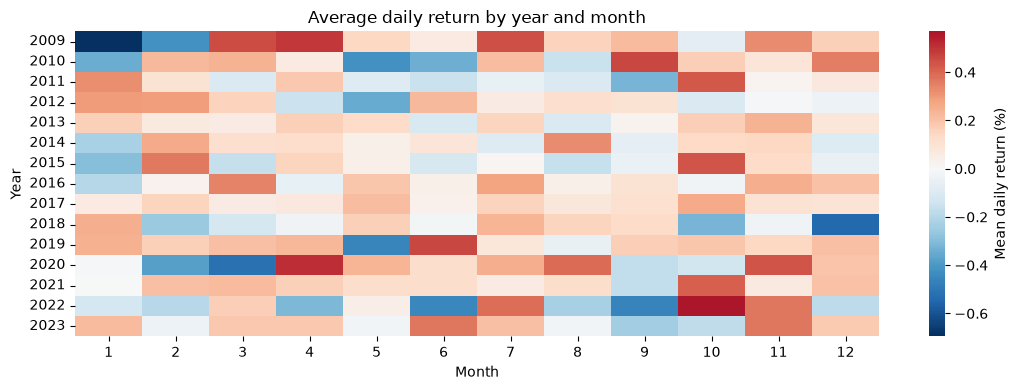

In [6]:
monthly = port.groupby([port.index.year, port.index.month]).mean().unstack()
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(monthly * 100, cmap='RdBu_r', center=0, ax=ax, cbar_kws={'label': 'Mean daily return (%)'})
ax.set_title('Average daily return by year and month')
ax.set_xlabel('Month')
ax.set_ylabel('Year')
fig.tight_layout()
fig.savefig(F / 'eda_seasonality.png', dpi=150, bbox_inches='tight')
plt.show()

**Finding.** Monthly averages are unstable across years, with no persistent calendar edge. **Consequence.** Calendar features are kept as controls but should not dominate; the report does not claim a seasonal trading rule.

In [7]:
rows = []
for t in equities:
    p = prices[prices['ticker'] == t].sort_values('date')['adj_close']
    ret = np.log(p).diff().dropna()
    rows.append({
        'ticker': t,
        'ADF price p': adfuller(p.dropna())[1],
        'ADF return p': adfuller(ret)[1],
        'skew': skew(ret),
        'excess_kurtosis': kurtosis(ret),
    })
adf = pd.DataFrame(rows)
adf.to_csv(path_from_config(cfg, 'reports') / 'eda_adf.csv', index=False)
adf.round(4)

C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF price p': adfuller(p.dropna())[1],
C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF return p': adfuller(ret)[1],


C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF price p': adfuller(p.dropna())[1],
C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF return p': adfuller(ret)[1],


C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF price p': adfuller(p.dropna())[1],
C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF return p': adfuller(ret)[1],


C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF price p': adfuller(p.dropna())[1],
C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF return p': adfuller(ret)[1],


C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF price p': adfuller(p.dropna())[1],
C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF return p': adfuller(ret)[1],


C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF price p': adfuller(p.dropna())[1],
C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF return p': adfuller(ret)[1],


C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF price p': adfuller(p.dropna())[1],
C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF return p': adfuller(ret)[1],


C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF price p': adfuller(p.dropna())[1],
C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF return p': adfuller(ret)[1],


C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF price p': adfuller(p.dropna())[1],
C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF return p': adfuller(ret)[1],


C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF price p': adfuller(p.dropna())[1],
C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2888172442.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF return p': adfuller(ret)[1],


,ticker,ADF price p,ADF return p,skew,excess_kurtosis
0,AAPL,0.9946,0.0,-0.2016,4.9148
1,MSFT,0.9987,0.0,-0.2171,8.0077
2,NVDA,0.9989,0.0,0.1433,6.4971
3,JPM,0.9668,0.0,0.4303,19.3632
4,XOM,0.9003,0.0,-0.1528,6.8949
5,JNJ,0.8454,0.0,-0.3461,9.1115
6,PG,0.9345,0.0,-0.0926,10.0381
7,KO,0.8149,0.0,-0.6366,8.8540
8,CAT,0.9811,0.0,-0.1681,4.3205
9,HD,0.9651,0.0,-0.8265,16.6497


**Finding.** The ADF p-value is above 0.05 for every price series and below 0.05 for every return series. **Consequence.** Returns are the modelling target (PRD Section 6.1), and price-space metrics are reported only for comparability. Return kurtosis confirms the fat-tail decision above.

## Distribution diagnostics: QQ plot and Jarque-Bera

The histogram is not enough to justify the fat-tail decision; the QQ plot and the Jarque-Bera test check the normal assumption directly.

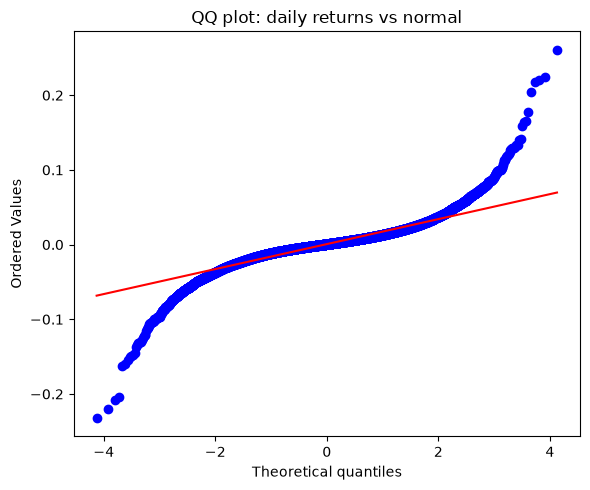

,ticker,JB,p_value
0,AAPL,3823.0362,0.0
1,MSFT,10110.2763,0.0
2,NVDA,6648.9557,0.0
3,JPM,59059.3284,0.0
4,XOM,7488.3576,0.0
5,JNJ,13126.5890,0.0
6,PG,15846.2597,0.0
7,KO,12579.0069,0.0
8,CAT,2952.2762,0.0
9,HD,44009.5758,0.0


In [8]:
from scipy import stats

fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(r, dist='norm', plot=ax)
ax.set_title('QQ plot: daily returns vs normal')
fig.tight_layout()
fig.savefig(F / 'eda_qq.png', dpi=150, bbox_inches='tight')
plt.show()

jb_rows = []
for t in equities:
    x = np.log(prices[prices['ticker'] == t].sort_values('date')['adj_close']).diff().dropna()
    stat, p = stats.jarque_bera(x)
    jb_rows.append({'ticker': t, 'JB': stat, 'p_value': p})
jb = pd.DataFrame(jb_rows)
jb.to_csv(path_from_config(cfg, 'reports') / 'eda_jarque_bera.csv', index=False)
jb.round(4)

**Finding.** The QQ plot bends away from the 45-degree line in both tails and the Jarque-Bera p-values reject normality for every ticker. **Consequence.** Risk reporting uses drawdown and empirical/Student-t VaR alongside volatility, and the neural nets use Huber loss rather than squared error.

## Day-of-week averages and STL decomposition

The PRD asks for calendar seasonality to be checked, not assumed.

C:\Users\naman\AppData\Local\Temp\ipykernel_133672\2144760499.py:1: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = port.groupby(port.index.dayofweek).mean() * 100


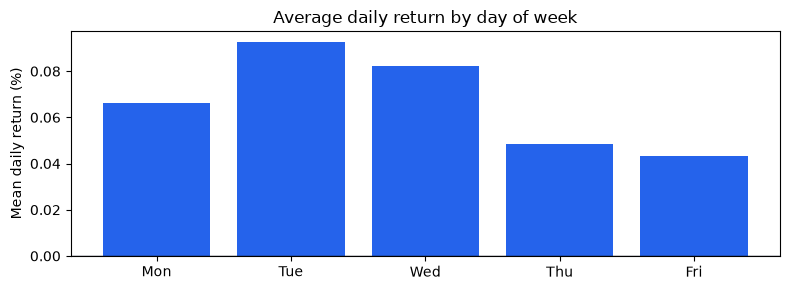

date
0    0.066271
1    0.092627
2    0.082097
3    0.048559
4    0.043170
dtype: float64

In [9]:
dow = port.groupby(port.index.dayofweek).mean() * 100
labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri'][: len(dow)]
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(labels, dow.to_numpy(), color='#2563eb')
ax.axhline(0, color='#0f172a', linewidth=1)
ax.set_ylabel('Mean daily return (%)')
ax.set_title('Average daily return by day of week')
fig.tight_layout()
fig.savefig(F / 'eda_dow.png', dpi=150, bbox_inches='tight')
plt.show()
dow

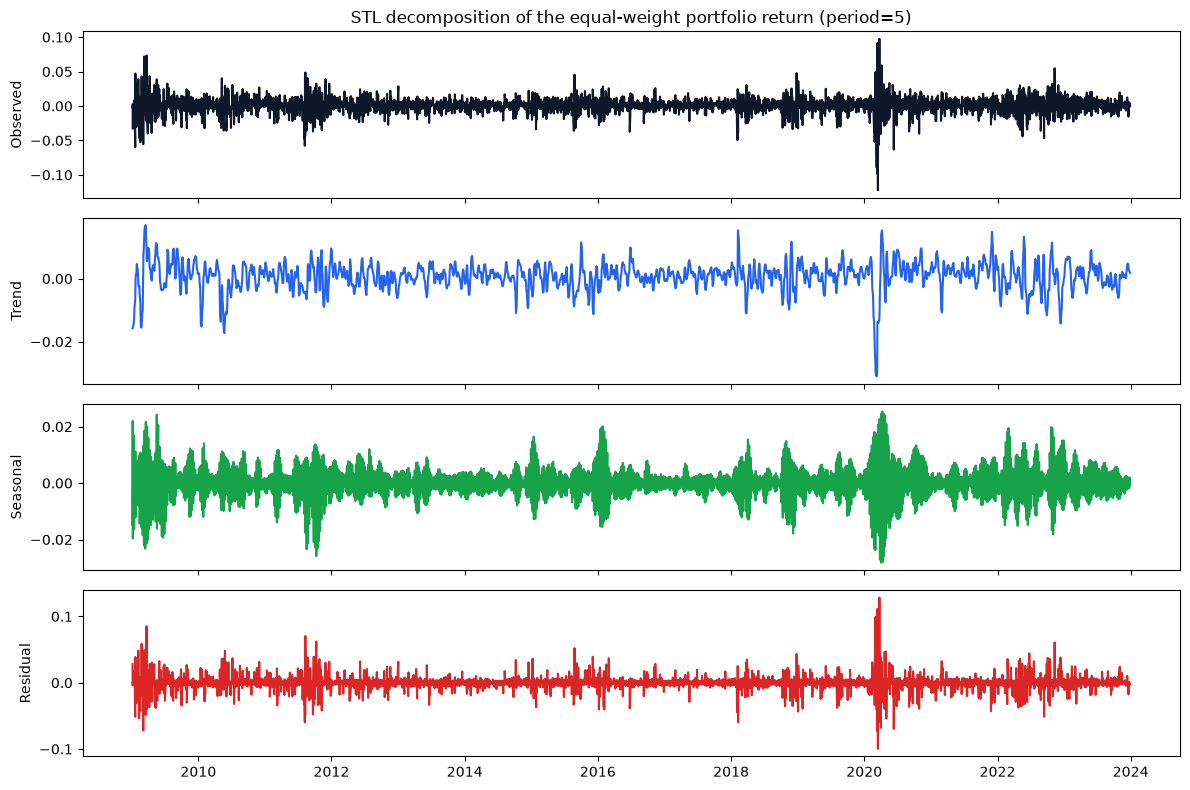

In [10]:
from statsmodels.tsa.seasonal import STL

series = port.dropna()
stl = STL(series, period=5, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
axes[0].plot(series.index, series, color='#0f172a'); axes[0].set_ylabel('Observed')
axes[1].plot(series.index, stl.trend, color='#2563eb'); axes[1].set_ylabel('Trend')
axes[2].plot(series.index, stl.seasonal, color='#16a34a'); axes[2].set_ylabel('Seasonal')
axes[3].plot(series.index, stl.resid, color='#dc2626'); axes[3].set_ylabel('Residual')
axes[0].set_title('STL decomposition of the equal-weight portfolio return (period=5)')
fig.tight_layout()
fig.savefig(F / 'eda_stl.png', dpi=150, bbox_inches='tight')
plt.show()

**Finding.** Day-of-week averages are small and change sign across the sample; the STL seasonal component is tiny relative to the trend and residual. **Consequence.** Calendar features are controls, not a claimed trading edge.

## Hypotheses handed to the modelling stage

1. Returns are stationary; a random walk is a hard baseline for h=1.
2. Momentum/trend and volatility-regime features carry more signal than calendar effects.
3. Fat tails require Huber loss for neural nets and drawdown/VaR in reporting.
4. Cross-asset correlations are low enough for mean-variance optimisation to help.
5. News sentiment may help direction more than MAE; the ablation reports both.